# Member 2 — Controlled feature comparison

This notebook asks one controlled question: **does adding past demand history improve 2024 district-week forecasting compared with district and calendar features alone?**

Only the feature columns change. All experiments use the same 2020–2023 rows, 2024 validation rows, target values, preprocessing design, and Poisson model settings. The 2025 final-test period is not loaded into evaluation, inspected, tuned on, or scored. Results remain **provisional** because fixed current geography and annual source coverage are not approved assumptions.

In [1]:
from pathlib import Path
import hashlib
import json
import platform
import sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display, Image

root = Path.cwd().resolve()
while not (root / 'src' / 'feature_comparison.py').exists():
    if root == root.parent:
        raise RuntimeError('Run this notebook from within the project repository.')
    root = root.parent
sys.path.insert(0, str(root / 'src'))

from eda_features import add_forecasting_features, build_shared_development_panel
from feature_comparison import FEATURE_GROUPS, MODEL_CONFIGURATION, run_feature_comparison

data_path = root / 'data/processed/illegal_dumping_cleaned.csv'
boundary_path = root / 'data/reference/council_districts_snapshot.geojson'
team_metrics_path = root / 'results/demand_forecasting/validation_metrics.csv'
team_predictions_path = root / 'results/demand_forecasting/validation_predictions.csv'
metrics_path = root / 'results/member2/feature_comparison_metrics.csv'
predictions_path = root / 'results/member2/feature_comparison_predictions.csv'
figure_path = root / 'reports/figures/member2/feature_comparison.png'

print('Python:', platform.python_version(), '| pandas:', pd.__version__, '| scikit-learn:', sklearn.__version__)
print('Model configuration:', MODEL_CONFIGURATION)

Python: 3.11.15 | pandas: 2.3.3 | scikit-learn: 1.6.1
Model configuration: PoissonRegressor(alpha=1.0,max_iter=2000,tol=1e-8)


## 1. Predeclared feature groups

- **A — Basic:** district, month, ISO week of year, and sine/cosine annual seasonality.
- **B — Basic + lags:** A plus demand 1, 2, 4, and 8 completed weeks earlier.
- **C — Basic + lags + rolling:** B plus 4-, 8-, and 13-week means, 4- and 8-week standard deviations, and last-week demand relative to its four-week mean.

District is one-hot encoded. Every numeric input is standardized. The encoder and scaler are fitted only on 2020–2023 training rows. Every experiment uses `PoissonRegressor(alpha=1, max_iter=2000, tol=1e-8)` with no tuning. Poisson regression models a non-negative expected request count from a linear combination of the transformed inputs.

In [2]:
# Explicit opt-in preserves team compatibility without claiming assumptions are approved.
ACCEPT_PROVISIONAL_GEOGRAPHY = True
ACCEPT_PROVISIONAL_COVERAGE = True
base_panel = build_shared_development_panel(
    data_path, boundary_path, preserve_team_zero_fill=True
)
featured_panel = add_forecasting_features(base_panel)
input_sha256 = hashlib.sha256(data_path.read_bytes()).hexdigest()
boundary_sha256 = hashlib.sha256(boundary_path.read_bytes()).hexdigest()
panel_audit = pd.Series({
    'district_week_rows': len(base_panel),
    'districts': base_panel['district'].nunique(),
    'weeks': base_panel['week_start'].nunique(),
    'complete_week_target_sum': int(base_panel['count'].sum()),
    'provisional_zero_filled_rows': int(base_panel['provisional_zero_filled'].sum()),
    'latest_week_start': base_panel['week_start'].max(),
    '2025_panel_rows': int(base_panel['week_start'].dt.year.ge(2025).sum()),
    'cleaned_input_sha256': input_sha256,
    'boundary_sha256': boundary_sha256,
}, name='value')
display(panel_audit.to_frame())
display(pd.Series(FEATURE_GROUPS, name='numeric_features').to_frame())
assert len(base_panel) == 3_650
assert base_panel['district'].nunique() == 10
assert base_panel['week_start'].max() == pd.Timestamp('2024-12-23')
assert not base_panel['week_start'].dt.year.ge(2025).any()

,value
district_week_rows,3650
districts,10
weeks,365
complete_week_target_sum,180732
provisional_zero_filled_rows,0
latest_week_start,2024-12-23 00:00:00
2025_panel_rows,0
cleaned_input_sha256,c075709e37fa3050f5d53c94fb9db486e169c44a13d2fd...
boundary_sha256,29ba080e546a747541716349e4c0620923a751322ea37a...


,numeric_features
A_basic,"[month, week_of_year, sin_year, cos_year]"
B_basic_lags,"[month, week_of_year, sin_year, cos_year, lag_..."
C_basic_lags_rolling,"[month, week_of_year, sin_year, cos_year, lag_..."


## 2. Fit and evaluate on identical rows

The runner refuses to fit unless provisional geography and coverage are explicitly acknowledged. It selects one common training frame and one common validation frame before looping over feature groups, preventing a stronger model from receiving easier rows. No random split is used.

**MAE** is the average absolute difference between predicted and actual requests; it describes the typical error size. **RMSE** squares errors first, so unusually large misses receive more weight. Lower values are better for both.

In [3]:
comparison = run_feature_comparison(
    featured_panel,
    accept_provisional_geography=ACCEPT_PROVISIONAL_GEOGRAPHY,
    accept_provisional_coverage=ACCEPT_PROVISIONAL_COVERAGE,
)
metrics_output = comparison.metrics.copy()
metrics_output['training_period'] = '2020-2023'
metrics_output['validation_period'] = '2024'
metrics_output['model_configuration'] = MODEL_CONFIGURATION
metrics_output['cleaned_input_sha256'] = input_sha256
metrics_output['boundary_sha256'] = boundary_sha256
metrics_output['provisional_zero_filled_rows'] = int(base_panel['provisional_zero_filled'].sum())
metrics_output['status'] = 'provisional_pending_geography_and_coverage_approval'
display(metrics_output)

assert metrics_output['train_rows'].eq(2_080).all()
assert metrics_output['validation_rows'].eq(520).all()
assert comparison.validation_frame['district'].nunique() == 10
assert comparison.validation_frame['week_start'].nunique() == 52
assert comparison.validation_frame['week_start'].min() == pd.Timestamp('2024-01-01')
assert comparison.validation_frame['week_start'].max() == pd.Timestamp('2024-12-23')
assert not comparison.validation_frame['week_start'].dt.year.ge(2025).any()

reference_train = comparison.training_keys['A_basic']
reference_validation = comparison.validation_keys['A_basic']
for experiment in FEATURE_GROUPS:
    pd.testing.assert_frame_equal(reference_train, comparison.training_keys[experiment])
    pd.testing.assert_frame_equal(reference_validation, comparison.validation_keys[experiment])
target_pivot = comparison.predictions.pivot(
    index=['district', 'week_start'], columns='experiment', values='actual_count'
)
assert target_pivot.nunique(axis=1).eq(1).all()
print('VERIFIED: all experiments use identical training keys, validation keys, and actual targets.')

,experiment,numeric_feature_count,total_model_inputs,train_rows,validation_rows,mae,rmse,mae_change_vs_basic,mae_improvement_percent_vs_basic,rmse_change_vs_basic,rmse_improvement_percent_vs_basic,training_period,validation_period,model_configuration,cleaned_input_sha256,boundary_sha256,provisional_zero_filled_rows,status
0,A_basic,4,5,2080,520,17.860695,24.531908,0.00000,0.000000,0.000000,0.000000,2020-2023,2024,"PoissonRegressor(alpha=1.0,max_iter=2000,tol=1...",c075709e37fa3050f5d53c94fb9db486e169c44a13d2fd...,29ba080e546a747541716349e4c0620923a751322ea37a...,0,provisional_pending_geography_and_coverage_app...
1,B_basic_lags,8,9,2080,520,13.851855,19.482256,-4.00884,22.445041,-5.049652,20.584015,2020-2023,2024,"PoissonRegressor(alpha=1.0,max_iter=2000,tol=1...",c075709e37fa3050f5d53c94fb9db486e169c44a13d2fd...,29ba080e546a747541716349e4c0620923a751322ea37a...,0,provisional_pending_geography_and_coverage_app...
2,C_basic_lags_rolling,14,15,2080,520,14.131035,19.780809,-3.72966,20.881942,-4.751098,19.367016,2020-2023,2024,"PoissonRegressor(alpha=1.0,max_iter=2000,tol=1...",c075709e37fa3050f5d53c94fb9db486e169c44a13d2fd...,29ba080e546a747541716349e4c0620923a751322ea37a...,0,provisional_pending_geography_and_coverage_app...


VERIFIED: all experiments use identical training keys, validation keys, and actual targets.


## 3. Compatibility with the existing team result

The teammate's 2020-start Poisson result uses the same model configuration, train/validation periods, preprocessing convention, map, and target construction, but a different feature set: district, lags 1/2/4, rolling means 4/13, and sine/cosine seasonality. Therefore its metric is useful context, but it is not one of this ablation's predeclared A/B/C groups.

In [4]:
team_predictions = pd.read_csv(team_predictions_path, parse_dates=['week_start'])
team_poisson_predictions = (team_predictions.loc[team_predictions['experiment'].eq('poisson_2020')]
                            .sort_values(['week_start', 'district']).reset_index(drop=True))
ours = (comparison.predictions.loc[comparison.predictions['experiment'].eq('A_basic')]
        .sort_values(['week_start', 'district']).reset_index(drop=True))
pd.testing.assert_frame_equal(
    team_poisson_predictions[['district', 'week_start']].astype({'district': 'int64'}),
    ours[['district', 'week_start']].astype({'district': 'int64'}),
)
np.testing.assert_array_equal(team_poisson_predictions['count'].to_numpy(), ours['actual_count'].to_numpy())
team_metrics = pd.read_csv(team_metrics_path)
team_poisson_metric = team_metrics.loc[
    team_metrics['model'].eq('poisson') & team_metrics['training_start'].eq(2020),
    ['model', 'training_start', 'train_rows', 'validation_rows', 'mae', 'rmse'],
]
context = pd.concat([
    team_poisson_metric.assign(configuration='existing_team_poisson').drop(columns=['model', 'training_start']),
    metrics_output[['train_rows', 'validation_rows', 'mae', 'rmse']].assign(
        configuration=metrics_output['experiment'].to_numpy()),
], ignore_index=True)
display(context[['configuration', 'train_rows', 'validation_rows', 'mae', 'rmse']])
print('VERIFIED: the existing team Poisson result and this experiment use identical 2024 keys and targets.')

,configuration,train_rows,validation_rows,mae,rmse
0,existing_team_poisson,2080,520,13.642699,19.131701
1,A_basic,2080,520,17.860695,24.531908
2,B_basic_lags,2080,520,13.851855,19.482256
3,C_basic_lags_rolling,2080,520,14.131035,19.780809


VERIFIED: the existing team Poisson result and this experiment use identical 2024 keys and targets.


## 4. Save Member 2 evidence and interpret validation

Positive improvement percentages mean lower error than Experiment A. The best group is selected only on the predeclared 2024 validation comparison. That does not guarantee improvement in reserved 2025 because reporting patterns, channel systems, and demand relationships can change.

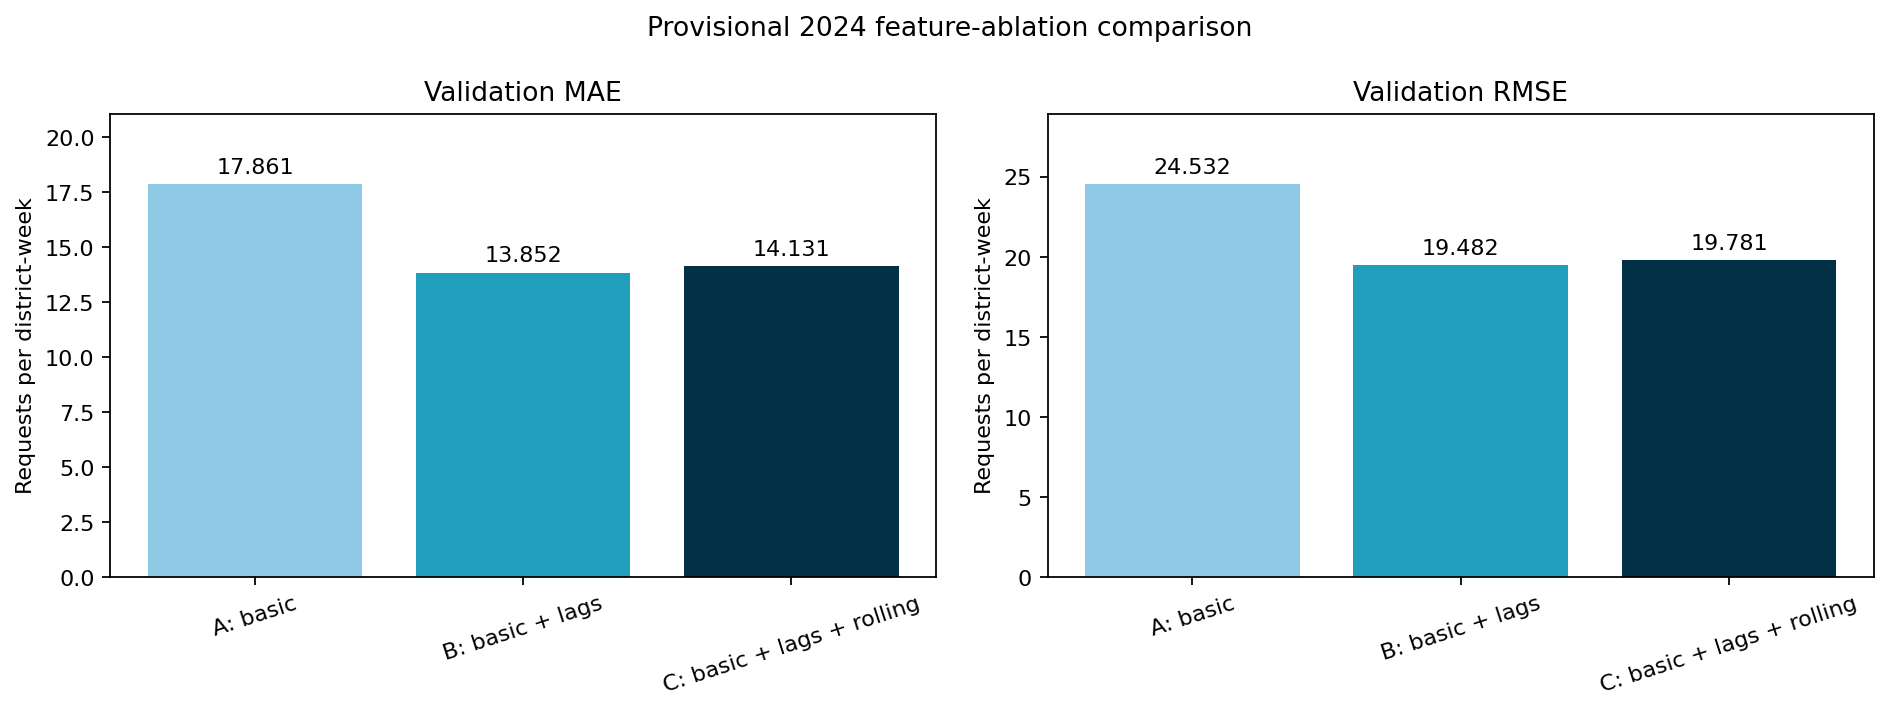

Saved metrics: results/member2/feature_comparison_metrics.csv
Saved predictions: results/member2/feature_comparison_predictions.csv
Saved figure: reports/figures/member2/feature_comparison.png
Best 2024 validation group by MAE: B_basic_lags (MAE=13.852, RMSE=19.482).


In [5]:
metrics_path.parent.mkdir(parents=True, exist_ok=True)
figure_path.parent.mkdir(parents=True, exist_ok=True)
metrics_output.to_csv(metrics_path, index=False)
comparison.predictions.to_csv(predictions_path, index=False)

labels = {'A_basic': 'A: basic', 'B_basic_lags': 'B: basic + lags',
          'C_basic_lags_rolling': 'C: basic + lags + rolling'}
plot_table = metrics_output.set_index('experiment')
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for axis, metric, title in zip(axes, ['mae', 'rmse'], ['Validation MAE', 'Validation RMSE']):
    values = plot_table[metric]
    bars = axis.bar([labels[index] for index in values.index], values.values, color=['#8ECAE6', '#219EBC', '#023047'])
    axis.bar_label(bars, labels=[f'{value:.3f}' for value in values], padding=3)
    axis.set(title=title, ylabel='Requests per district-week')
    axis.tick_params(axis='x', rotation=18)
    axis.set_ylim(0, values.max() * 1.18)
fig.suptitle('Provisional 2024 feature-ablation comparison')
fig.tight_layout()
fig.savefig(figure_path, dpi=160, bbox_inches='tight')
plt.close(fig)
display(Image(filename=str(figure_path)))

best = metrics_output.sort_values(['mae', 'rmse']).iloc[0]
print('Saved metrics:', metrics_path.relative_to(root))
print('Saved predictions:', predictions_path.relative_to(root))
print('Saved figure:', figure_path.relative_to(root))
print(f"Best 2024 validation group by MAE: {best['experiment']} "
      f"(MAE={best['mae']:.3f}, RMSE={best['rmse']:.3f}).")

In [6]:
all_numeric = list(dict.fromkeys(feature for group in FEATURE_GROUPS.values() for feature in group))
checks = pd.Series({
    'three_experiments': len(metrics_output) == 3,
    'identical_train_rows': metrics_output['train_rows'].nunique() == 1 and metrics_output['train_rows'].iloc[0] == 2_080,
    'identical_validation_rows': metrics_output['validation_rows'].nunique() == 1 and metrics_output['validation_rows'].iloc[0] == 520,
    'validation_keys_are_520_unique_rows': len(reference_validation.drop_duplicates()) == 520,
    'targets_identical': target_pivot.nunique(axis=1).eq(1).all(),
    'features_finite': np.isfinite(comparison.training_frame[all_numeric].to_numpy(dtype=float)).all() and np.isfinite(comparison.validation_frame[all_numeric].to_numpy(dtype=float)).all(),
    'metrics_finite': np.isfinite(metrics_output[['mae', 'rmse']].to_numpy()).all(),
    'predictions_finite': np.isfinite(comparison.predictions['prediction']).all(),
    'predictions_nonnegative': comparison.predictions['prediction'].ge(0).all(),
    'no_2025_evaluation': not comparison.training_frame['week_start'].dt.year.ge(2025).any() and not comparison.validation_frame['week_start'].dt.year.ge(2025).any(),
    'team_validation_targets_compatible': np.array_equal(team_poisson_predictions['count'], ours['actual_count']),
    'member2_outputs_exist': metrics_path.exists() and predictions_path.exists() and figure_path.exists(),
}, name='passed')
display(checks.to_frame())
assert checks.all()
print('All Phase 4 row, target, leakage, finiteness, compatibility, and output checks passed.')

,passed
three_experiments,True
identical_train_rows,True
identical_validation_rows,True
validation_keys_are_520_unique_rows,True
targets_identical,True
features_finite,True
metrics_finite,True
predictions_finite,True
predictions_nonnegative,True
no_2025_evaluation,True


All Phase 4 row, target, leakage, finiteness, compatibility, and output checks passed.


## 5. Interpretation limits

- This is a validation feature comparison, not final-test evidence.
- Repeatedly trying many features against 2024 could overfit validation; these three groups were declared before evaluation.
- The local current/2021 district map is applied retrospectively to earlier requests.
- Source completeness and the semantic validity of zero demand remain provisional, even though the current grid required no zero-filled cells.
- 311 counts measure reports, not all dumping incidents.
- The selected group, shared data hashes, preprocessing, and model must be frozen before any final 2025 evaluation.